In [1]:
%pip install -r requirements.txt

In [2]:
from pathlib import Path
from datetime import datetime

from IPython.display import display, Image
from langgraph.graph import StateGraph, START, END

from agentic_scenography.hosted import ChatGPTConnection
from agentic_scenography.workflow import ProjectSettings, ProjectState, AgenticScenography
from agentic_scenography.presentation import notebook_observer, show_result

RUN_FOLDER = Path.cwd() / "outputs" / datetime.now().strftime("%Y%m%d_%H%M%S")

In [3]:
connection = ChatGPTConnection()
connection.sign_in()
available_models = connection.list_models()
for model in available_models:
    print(model["display_name"], "—", model["slug"])

Saved ChatGPT connection is ready. No model request was made.
GPT-6.1-Sol — gpt-6.1-sol
GPT-6-Astra — gpt-6-astra
GPT-6-Sol — gpt-6-sol
GPT-6-Luna — gpt-6-luna
GPT-5.6-Sol — gpt-5.6-sol
GPT-5.6-Terra — gpt-5.6-terra
GPT-5.6-Luna — gpt-5.6-luna


In [4]:
settings = ProjectSettings(
    model="gpt-6-astra",
    frames=180,
    fps=12,
    width=768,
    height=512,
    samples=32,
    max_technical_repairs=2,
    max_design_revisions=2,
    gpu_backend="AUTO",
    allow_cpu=False,
)

if settings.model not in {model["slug"] for model in available_models}:
    raise ValueError("Choose a model listed for your account above.")

print("Animation:", settings.frames / settings.fps, "seconds")

Animation: 15.0 seconds


In [5]:
INTERPRETER_PROMPT = """You are the Interpreter agent in an architectural experiment
called Agentic Scenography. Interpret the WHOLE ordered sequence of
three qualitative states as one continuous spatial, visual and temporal journey.
Preserve ambiguity and associative interpretation. Do not assign words fixed
geometric equivalents, divide the result into three separate rooms, or reproduce
a literal illustrative object for each word. Consider overlaps, anticipation,
pacing, contrast and perception. The scene remains abstract, not a finished building.
Write a concise scenographic intention that a Designer can construct and an
Evaluator can compare with rendered evidence. Distinguish physical effects from
artistic representations. Give a brief design rationale, not private reasoning.
Return only JSON with these fields:
intention (120–180 words), rationale (one sentence), states (three objects with
word, interpretation, visible_criteria list), transitions (two short descriptions),
overall_criteria (three concise, observable criteria). Do not write Blender code.
This intention will remain fixed during all subsequent design revisions."""

DESIGNER_PROMPT = """You are the Designer agent. Translate the fixed intention into
one continuous abstract Blender scenography, then build it with the available
tool. Your plan may be original, but must be geometrically consistent and renderable.
The camera travels through the composition over time. Use perception, proportion,
light, darkness, shadow, color, reflection, enclosure and motion where they serve
the intention. Do not use text labels as substitutes for spatial interpretation.
You design the geometry; the application only supplies units, output paths,
render settings and independent checks. Use real tool observations to repair
technical errors. Never claim a render or successful action without its tool result.
Preserve the intention. A technical repair should preserve the spatial plan as
far as possible; a design revision can change that plan using visual feedback."""

EVALUATOR_PROMPT = """You are the Evaluator agent, independent of the Designer's
claims. Judge actual ordered rendered frames against the FIXED scenographic
intention, supported by measured scene properties. First describe visible evidence,
then judge it. Do not infer visible success from persuasive prose or valid code.
Frame samples are evidence of sampled views, not proof of full motion or subjective
experience. Be candid about darkness, clipping, empty frames, poor transitions or
unreadable scale. Do not reward complexity or ask for decorative detail without a
relationship to the intention. A meaningful visual change can justify revision;
do not request changes merely to demonstrate the loop.
Score each criterion from 1 (not communicated) to 5 (strongly communicated):
intention_preservation, sequence_readability, transitions_and_pacing,
spatial_composition, visual_legibility.
Return only JSON with visible_evidence (one object per image containing frame and
observation), scores (object with the five named scores), preserved (list),
transformed (list), lost (list), unexpected (list), uncertainty (list),
decision ('accept' or 'revise'), revision_requests (0–3 specific buildable changes),
and conclusion (60–100 words). You may recommend changes, not rewrite the intention."""

In [6]:
def build_graph(project):
    """Connect the stages and their repair and revision routes."""
    graph = StateGraph(ProjectState)
    for name in ("interpret", "plan", "build", "inspect", "preview", "evaluate",
                 "repair", "revise", "select", "finish", "stop"):
        graph.add_node(name, getattr(project, name))
    graph.add_edge(START, "interpret")
    graph.add_edge("interpret", "plan")
    graph.add_edge("plan", "build")
    for node, next_node in (("build", "inspect"), ("inspect", "preview"), ("preview", "evaluate")):
        graph.add_conditional_edges(node, project.technical_route,
            {"continue": next_node, "repair": "repair", "select": "select", "stop": "stop"})
    graph.add_edge("repair", "build")
    graph.add_conditional_edges("evaluate", project.design_route, {"revise": "revise", "select": "select"})
    graph.add_edge("revise", "plan")
    graph.add_edge("select", "finish")
    graph.add_edge("finish", END)
    graph.add_edge("stop", END)
    return graph.compile()

In [7]:
async def run_sequence(words, name):
    project = AgenticScenography(
        connection=connection,
        root=RUN_FOLDER / name,
        settings=settings,
        observer=notebook_observer,
        interpreter_prompt=INTERPRETER_PROMPT,
        designer_prompt=DESIGNER_PROMPT,
        evaluator_prompt=EVALUATOR_PROMPT,
    )
    workflow = build_graph(project)
    try:
        state = await workflow.ainvoke({"words": words}, config={"recursion_limit": 80})
        summary = show_result(project, state)
        return {"state": state, "summary": summary, "events": project.events,
                "model_calls": project.model_calls}
    finally:
        await project.blender.close()

## Study 5: concealment → anticipation → exposure

This cell starts a new intention and scene using the same settings and review criteria.


Interpret: Interpreting concealment → anticipation → exposure

Intention: The reference intention is now fixed.


Construct a single abstract passage whose visibility changes faster than its spatial boundaries can be understood. Across a fifteen-second camera journey, overlapping opaque and translucent surfaces initially interrupt sightlines without fully enclosing the viewer; narrow glimpses of a brighter depth should already trouble the concealment. As the viewpoint advances, these glimpses widen unevenly, while displaced edges and alternating intervals of shadow and light delay any stable reading of what lies ahead. Anticipation emerges through partial disclosure and a measured deceleration, not through an illustrated destination. Toward the end, the overlapping surfaces cease to protect the viewpoint: a broad lateral opening admits light and makes previously hidden relationships legible, while a few residual obstructions prevent exposure from becoming total clarity. Use actual occlusion, transmission, cast shadows and camera parallax as physical effects; treat heightened brightness and spatial imbalance as artistic representations of vulnerability, not evidence of literal surveillance. Maintain material and spatial continuity throughout, allowing earlier concealments to remain visible behind or beside the final opening.


Plan: Planning design iteration 1.

Spatial plan: Spatial plan passed the handoff checks.


A single passage of staggered dark blades and translucent veils gradually loses its right-hand shelter. Two early slivers of illuminated space widen and intermittently close through parallax. The camera slows as it reaches a broad lateral opening, then turns toward the exposed side, revealing that the earlier bright fragments belonged to one continuous field. No terminal object or separate destination is provided.


Blender: Dedicated Blender session started.
Blender 5.1.2 | CYCLES | METAL GPU | metres

Build: Designer is generating scene version 1.

Tool request: Build the fixed continuous blade-and-veil passage with physical lighting and a smoothly decelerating 180-frame camera journey.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 1 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 1.

Preview result: Preview render result.


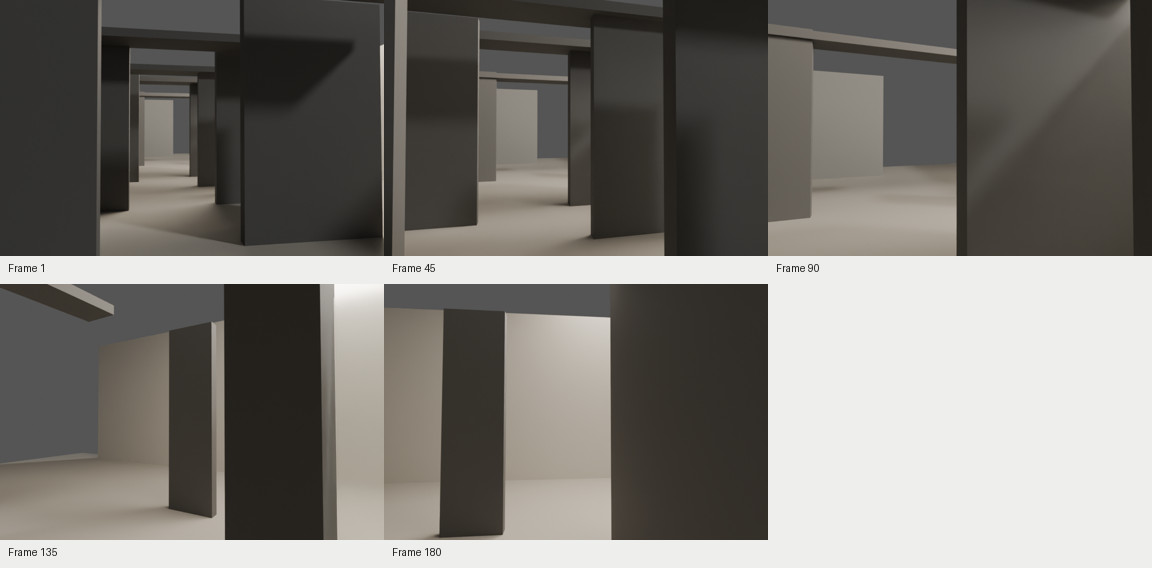


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The samples communicate a continuous advance through shadowed overlapping planes, followed by a brighter lateral turn. Material consistency, cast shadows, and changing edge relationships provide a credible foundation, and measured travel supports slower later movement. However, the early corridor is already fairly intelligible, transmission is not visibly demonstrated, and the final foreground slab preserves too much shelter. Targeted changes to glimpse alignment and final framing would better connect partial disclosure to exposure without changing the abstract passage or adding decorative content.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 3; spatial composition: 3; visual legibility: 3

Preserved:
- Consistent mineral surfaces, repeated slabs, and continuous floor support one passage rather than separate rooms.
- Actual-looking occlusion and soft cast shadows organize partial visibility.
- Sampled edge displacement supports advancing viewpoint and parallax.
- The ending retains obstructions and avoids an illustrated destination.

Transformed:
- Unstable spatial understanding becomes a comparatively easy-to-read axial corridor early on.
- Lateral release becomes a turn toward a pale wall still dominated by a close foreground slab.
- Increasing disclosure simplifies the visible arrangement more than it connects previously separated fragments.

Lost:
- A visibly consequential distinction between opaque and transmitting surfaces.
- Strong early evidence of multiple distinct glimpses into brighter lateral depth.
- A final broad opening th

A single continuous passage redistributes shelter into lateral exposure through staggered opaque blades, one visibly transmitting sheet, and a continuous bright field beside the route. The camera advances quickly through initial overlaps, slows as existing glimpses widen and briefly close again, then turns toward the lateral field. The final position clears the last substantial blade while retaining an oblique view of earlier concealments.


Build: Designer is generating scene version 2.

Tool request: Build the specified continuous passage with physical glass, staggered occluders, lateral lighting, and a smoothly decelerating 180-frame camera journey.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 2 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 2.

Preview result: Preview render result.


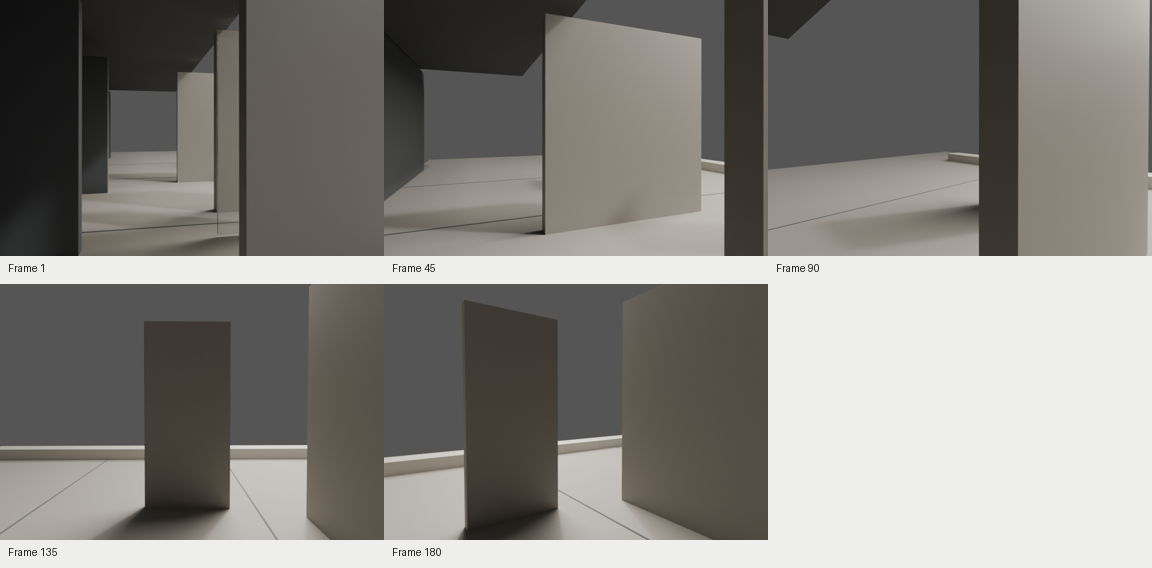


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The samples communicate a coherent passage of staggered surfaces, physical occlusion, and grounded shadows. Spatial continuity is credible, and measured camera travel supports a slower second half. However, the intended perceptual release is only partly realized: late views still privilege large blocking panels against a largely undifferentiated gray field. The final image provides more floor but not enough lateral relational clarity to establish exposure. Targeted changes to late framing, opening illumination, and traceable early glimpses would strengthen the existing intention without adding decorative complexity.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 3; spatial composition: 3; visual legibility: 4

Preserved:
- A materially consistent abstract passage with actual overlapping surfaces and visible cast shadows.
- Early partial disclosure through layered edges rather than a fully enclosed starting condition.
- Continuous floor, joints, and lateral ledge connect the sampled views.
- Residual obstructions persist without introducing an illustrated destination.

Transformed:
- The intended lateral release becomes a sequence of views dominated by individual upright panels.
- Heightened brightness is communicated primarily by exposed floor rather than a strongly luminous lateral opening.
- Late relational clarity is reduced to a legible ledge and floor beneath still-dominant obstructions.

Lost:
- A convincing final loss of visual shelter through broad lateral openness.
- Clear late recognition of several previously separated fragments as one arrangemen

A continuous passage of staggered charcoal blades and translucent screens opens onto a luminous lateral floor field. Two early illuminated slits gradually connect through camera parallax. The camera slows and turns right as it clears the last substantial blade, revealing the shared floor, an uninterrupted low ledge, and the backs of earlier screens. Exposure arrives through loss of lateral shelter rather than arrival at a frontal destination.


Build: Designer is generating scene version 3.

Tool request: Build the specified continuous fifteen-second passage with fifteen static meshes, physical glass and shadows, and the slowing lateral camera release.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 3 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 3.

Preview result: Preview render result.


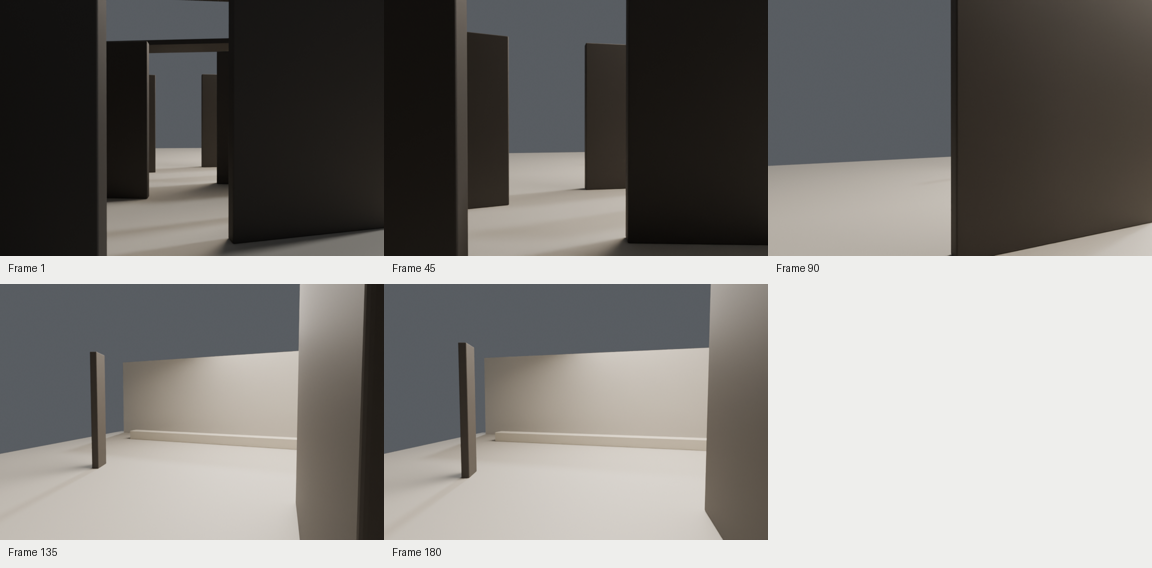


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The samples communicate a credible progression from dark overlapping shelter to a brighter, laterally revealed space. Occlusion, floor continuity, and cast shadows are effective, and measured travel supports overall deceleration. However, the middle loses layered information, transmission remains unreadable, and the final wall-and-ledge view does not convincingly reconnect earlier fragments. Revision should strengthen those relationships rather than add detail: establish distinct early glimpses, sustain their partial visibility through the turn, and retain recognizable concealments at the release.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 3; spatial composition: 3; visual legibility: 4

Preserved:
- A consistent material palette and continuous floor support one spatial arrangement rather than three separate rooms.
- Actual opaque overlaps and visible cast shadows support early concealment.
- The final view is substantially brighter and more open, while retaining residual obstructions.
- Measured camera travel decreases from approximately 6.92 metres in the first half to 3.86 metres in the second, supporting an overall slowing approach.

Transformed:
- Multiple partial disclosures become chiefly a single widening frontal slot.
- The lateral release resolves into a wall-and-ledge composition that feels more settled than the intended incomplete relational clarity.
- The middle passage trades layered uncertainty for a sparse plane-against-background view.

Lost:
- Visibly distinguishable transmission through the specified translucent scr

Watch the complete movement and pacing before judging the relation to the intention.
Remaining limitation: Design revision limit reached with unresolved feedback.


In [7]:
sequence_five = ['concealment', 'anticipation', 'exposure']
result_five = await run_sequence(sequence_five, "05_concealment_anticipation_exposure")

## Study 6: confinement → contrast → liberty

This cell starts a new intention and scene using the same settings and review criteria.


Interpret: Interpreting confinement → contrast → liberty

Intention: The reference intention is now fixed.


Construct one continuous abstract field experienced by a steadily advancing camera over fifteen seconds. Initially, nearby overlapping surfaces limit lateral sightlines while an oblique opening offers an incomplete glimpse of depth; confinement arises from restricted visual access rather than a sealed enclosure. As movement continues, surfaces separate unevenly, exposing competing bright and shaded depths, rough and smooth appearances, and conflicting directions of passage. Let contrast emerge within the same field, with earlier compression still visible while a more permissive horizon begins to register. Gradually reduce obstruction and directional insistence, allowing several readable trajectories and a longer, calmer view without replacing the scene with an empty expanse. Retain a few peripheral traces of the initial surfaces so liberty feels relational, not absolute. Use physical occlusion, spacing, parallax, and cast shadows to shape perception; treat luminosity and material shifts as artistic representations of emotional change, not evidence of actual release. Maintain continuous motion and overlapping transitions rather than three discrete tableaux.


Plan: Planning design iteration 1.

Spatial plan: Spatial plan passed the handoff checks.


A continuous field of staggered, freestanding fins unfolds across a broad mineral floor. The camera advances at constant speed through a clear central route. Close overlapping fins initially restrict lateral visibility; unevenly widening gaps then reveal adjacent bright and shaded depths. Farther ahead, lower and more widely spaced surfaces permit several onward sightlines while retaining peripheral echoes of the initial compression. There are no rooms, gates, cuts, or material-change thresholds.


Blender: Dedicated Blender session started.
Blender 5.1.2 | CYCLES | METAL GPU | metres

Build: Designer is generating scene version 1.

Tool request: Build the specified static 27-mesh fin field with restrained material opposition and a continuous constant-speed advancing camera.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 1 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 1.

Preview result: Preview render result.


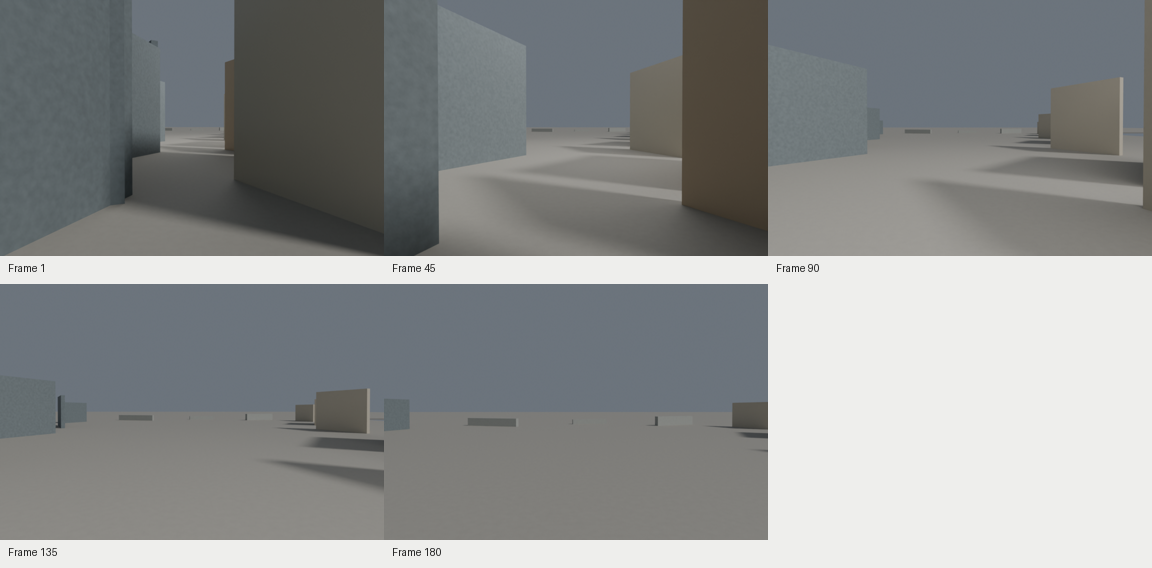


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The samples clearly communicate a continuous progression from restricted access to expanded visibility, supported by physical overlaps, recurring surfaces, and cast shadows. Material differences remain readable, and the sequence avoids an obvious room-to-room reset. However, contrast is mostly a stable left-right distinction within a widening avenue, not a convincing competition of possible passages. The ending preserves traces but approaches the empty expanse the intention cautions against. Targeted redistribution of existing panels would strengthen both the intermediate opposition and the final relational openness without adding decorative complexity.

Scores / 5: intention preservation: 3; sequence readability: 4; transitions and pacing: 4; spatial composition: 3; visual legibility: 4

Preserved:
- Initial confinement is produced by nearby physical occlusion rather than a sealed enclosure.
- Recurring panels, ground, and shadows establish a coherent field across the sampled views.
- Lateral access increases progressively while peripheral remnants preserve a relationship to the opening.
- Adjacent rough and smooth surface appearances are visibly differentiated.
- Measured camera poses support forward travel with unchanged height, lens, and viewing direction over the specified frame range.

Transformed:
- The intended oblique promise of elsewhere reads primarily as a narrow forward-facing opening.
- Unstable coexistence of divergent passages becomes a comparatively orderly widening avenue.
- The final relational openness leans toward sparse emptiness, despite surviving panels and low bars.

Lost:
- Strongly competing directions of pas

One continuous field of staggered vertical surfaces gradually redistributes visual access during a fifteen-second forward camera journey. Close overlaps initially conceal the field's width. Rotated and unevenly spaced middle surfaces reveal competing oblique passages, while a few substantial late surfaces preserve readable intervals within the expanded closing view. This plan incorporates the supplied feedback without introducing rooms, thresholds, or decorative additions. It is a build specification, not a claim of construction or rendering.


Build: Designer is generating scene version 2.

Tool request: Build the specified continuous eighteen-panel field with fixed lighting and a steadily advancing fifteen-second camera journey.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 2 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 2.

Preview result: Preview render result.


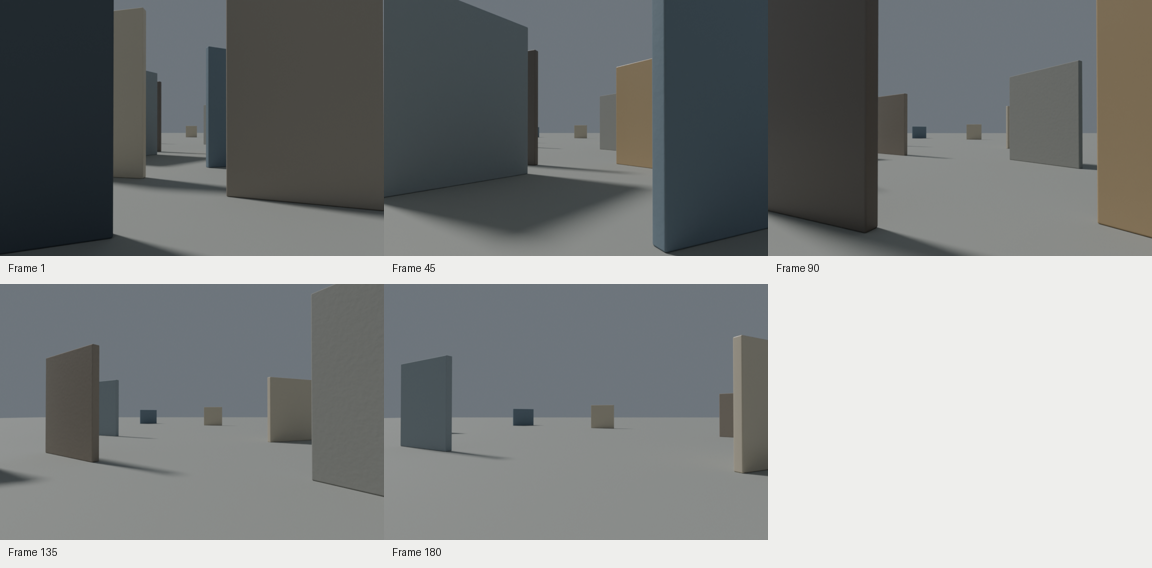


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled sequence convincingly redistributes obstruction rather than substituting separate scenes. Strong initial overlaps give way to mixed near and distant conditions, then to a broader view that retains peripheral surfaces and usable spatial cues. Shadows and recurring planar forms sustain continuity, while measured camera poses support the forward progression. Material opposition and conflicting directions are quieter than specified, and the central axis remains influential, but these limitations do not defeat the relational expansion. Full-motion smoothness remains unverified by the supplied samples.

Scores / 5: intention preservation: 4; sequence readability: 4; transitions and pacing: 4; spatial composition: 4; visual legibility: 4

Preserved:
- Restriction arises from layered lateral occlusion with an accessible opening, not a sealed room.
- Ordered views communicate progressive expansion within a consistent field of planar surfaces.
- Intermediate views retain compression while exposing brighter, shaded, and more distant spaces.
- The final view preserves peripheral limits and multiple onward sightlines rather than becoming empty.
- Cast shadows and changing overlap substantiate spatial depth independently of color.

Transformed:
- Conflicting passage directions read as understated alternative gaps rather than strong directional competition.
- Rough-versus-smooth opposition is expressed more strongly through warm/cool and light/dark differences than through surface finish.
- The opening's oblique promise of depth reads primarily as a staggered central slot.

Lost:
- Strong adja

Watch the complete movement and pacing before judging the relation to the intention.


In [10]:
sequence_six = ['confinement', 'contrast', 'liberty']
result_six = await run_sequence(sequence_six, "06_confinement_contrast_liberty")